# Deep Learning
## Practical Deep Learning Tutorial with PyTorch - Tutorial N° 2

### 2025-2026

# Importing necessary libraries

In [267]:
import torch
from torch.autograd import grad
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_moons

# Adaline

1. Build the ADALINE model using the `nn.Module` class. The model performs a linear transformation $\hat{y} = Xw^T + b$, with weights and bias initialised to zero.

In [268]:
class Adaline(torch.nn.Module):
    def __init__(self, num_features):
        super(Adaline, self).__init__()
        self.linear = torch.nn.Linear(num_features,1)                    # TODO
        torch.nn.init.zeros_(self.linear.weight)
        torch.nn.init.zeros_(self.linear.bias)
        # TODO : initialise weights and bias to zero

    def forward(self, x):
        activations = self.linear(x)
        return activations.view(-1)

2. Using 'iris.txt', create a binary dataset in 2-D : the last 100 instances of iris described only by the 2nd and 3rd features.

    Split the dataset into training and test sets (70%, 30%).

    Normalize the dataset. **Why must the mean and standard deviation be computed on the training set only?**

In [269]:
df = pd.read_csv('iris.txt', index_col=None, header=None)
df.columns = ['x1', 'x2', 'x3', 'x4', 'y']
df = df.iloc[50:150]                         # last 100 instances (2 last classes)
df['y'] = df['y'].apply(lambda x: 0 if x == 'Iris-versicolor' else 1)

# Assign features and target
X = torch.tensor(df[['x2', 'x3']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance)
mu, sigma =  X_train.mean(dim = 0) , X_train.std(dim = 0)    # TODO
X_train = (X_train - mu) / sigma        # TODO
X_test = (X_test - mu) / sigma        # TODO

In [270]:
model = Adaline(num_features=X_train.size(1))
model

Adaline(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

3. Train the model : we will use `MSELoss` (mean squared error) as loss function. The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

    The function `train` must **return the list of the loss values at each epoch**. Plot this cost curve.

In [271]:
def train(model, x, y, num_epochs, learning_rate, seed):
    cost = []
    torch.manual_seed(seed)
    optimizer = torch.optim.SGD(model.parameters(),lr = learning_rate )                 # TODO
    criterion = torch.nn.MSELoss()
    for e in range(num_epochs):
        # TODO : forward pass, loss, gradient reset, backward pass, update
        # TODO : store the loss of the epoch in cost
        predictions = model(x)
        loss = criterion(predictions, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        cost.append(loss.item())
        pass
    return cost

<function matplotlib.pyplot.show(close=None, block=None)>

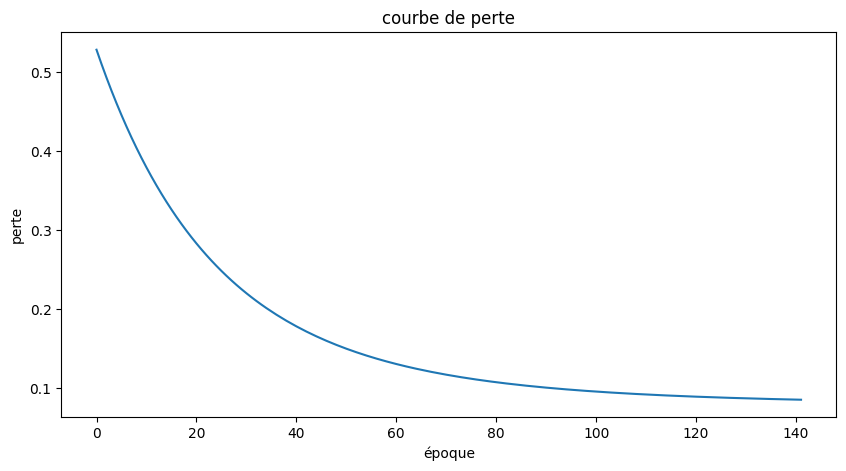

In [272]:
cost = train(model, X_train, y_train.float(), num_epochs=142, learning_rate=0.01, seed=123)
# TODO : plot the cost curve
plt.figure(figsize=(10,5))
plt.plot(cost)
plt.title('courbe de perte')
plt.xlabel('époque')
plt.ylabel('perte')
plt.show

4. Compute the model accuracy

In [273]:
def custom_where(cond, x_1, x_2):
    return (cond * x_1) + (torch.logical_not(cond) * x_2)

train_pred = model.forward(X_train)
train_acc = torch.mean((custom_where(train_pred > 0.5, 1, 0).int() == y_train).float())
test_pred = model.forward(X_test)
test_acc = torch.mean((custom_where(test_pred > 0.5, 1, 0).int() == y_test).float())
print('Training Accuracy: %.2f' % (train_acc*100))
print('Test Accuracy: %.2f' % (test_acc*100))
print('Weights', model.linear.weight)
print('Bias', model.linear.bias)

Training Accuracy: 92.86
Test Accuracy: 90.00
Weights Parameter containing:
tensor([[-0.0336,  0.3843]], requires_grad=True)
Bias Parameter containing:
tensor([0.4986], requires_grad=True)


5. a. Plot the training points (one color per class) and the decision boundary of the Adaline. Give the equation of this boundary as a function of $w_1$, $w_2$ and $b$ (be careful: the threshold is 0.5, not 0).

   b. Train a new Adaline for each learning rate in {0.001, 0.01, 0.1, 0.5} and plot the 4 cost curves on the same figure. What happens for the largest value? Explain.

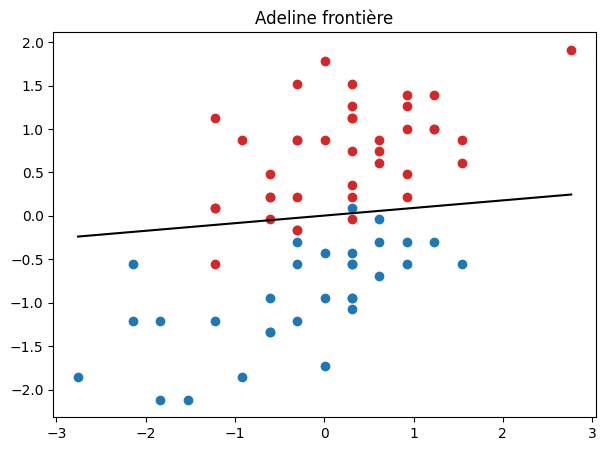

In [274]:
with torch.no_grad():
    w = model.linear.weight.detach()[0]
    b = model.linear.bias.item()
plt.figure(figsize=(7, 5))
for label, color in [(0, 'tab:blue'), (1, 'tab:red')]:
    pts = X_train[y_train == label]
    plt.scatter(pts[:, 0], pts[:, 1], color=color)

xs = torch.linspace(X_train[:, 0].min().item(), X_train[:, 0].max().item(), 500)
ys = (0.5 - b - w[0] * xs) / w[1]
plt.plot(xs, ys, 'k-')
plt.title('Adeline frontière')
plt.show()

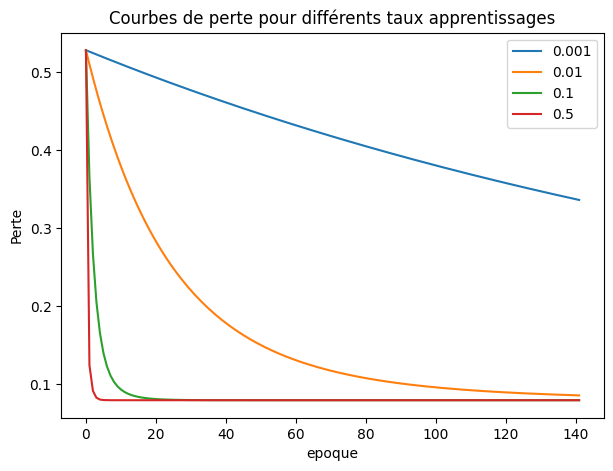

In [275]:
cost = []
i = 0
plt.figure(figsize=(7, 5))
for j in [0.001, 0.01, 0.1, 0.5] :
    m = Adaline(num_features=2)
    cost.append(train(m, X_train, y_train.float(), num_epochs=142, learning_rate=j, seed=123))
    plt.plot(cost[i],label = f'{j}')
    i = i + 1
plt.title('Courbes de perte pour différents taux apprentissages')
plt.xlabel('epoque')
plt.ylabel('Perte')
plt.legend()
plt.show()


Pour les valeurs les plus grandes, on obtient une perte très faible beaucoup plus rapidmeent.

# Perceptron

6. Build a Perceptron model **from scratch** (without autograd and without optimizer):
    - `forward` returns the predictions in {0, 1} (step function),
    - `backward` returns the errors $y - \hat{y}$,
    - `train` applies the perceptron learning rule example by example, and must **return the number of misclassified examples at each epoch**.

In [276]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

class Perceptron():
    def __init__(self, num_features):
        self.num_features = num_features
        self.weights = torch.zeros(num_features, 1, dtype=torch.float32, device=device)
        self.bias = torch.zeros(1, dtype=torch.float32, device=device)
        self.ones = torch.ones(1, device=device)
        self.zeros = torch.zeros(1, device=device)

    def forward(self, x):
        # TODO
        scores = x @ self.weights + self.bias
        return (scores >= 0).to(torch.float32)

    def backward(self, x, y):
        # TODO
        Y = self.forward(x).reshape(-1)
        return y.reshape(-1) - Y

    def train(self, x, y, epochs):
        n_errors = []
        for e in range(epochs):
            for i in range(y.shape[0]):
                xi = x[i].reshape(-1, 1)
                yi = y[i].reshape(1)
                errors = self.backward(xi.reshape(1, -1), yi)      # TODO
                self.weights = self.weights + errors * xi           # TODO
                self.bias = self.bias +  errors                     # TODO
            # TODO : count the misclassified examples after this epoch
            all_errors = self.backward(x, y)
            n_errors.append(int((all_errors != 0).sum().item()))
        return n_errors

    def evaluate(self, x, y):
        predictions = self.forward(x).reshape(-1)
        accuracy = torch.sum(predictions == y).float() / y.shape[0]
        return accuracy

7. Load the 'perceptron_toydata' dataset

    Split the dataset into train and test sets

    Normalize the data

In [277]:
df = pd.read_csv('perceptron_toydata.txt', index_col=None, header=None, delimiter='\t')
df.columns = ['x1', 'x2', 'y']
X = torch.tensor(df[['x1', 'x2']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)
print('Class label counts:', torch.bincount(y))
print('X.shape:', X.shape)
print('y.shape:', y.shape)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance)
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

Class label counts: tensor([50, 50])
X.shape: torch.Size([100, 2])
y.shape: torch.Size([100])


8. Train the perceptron and plot the number of errors per epoch.

Model parameters:
  Weights: tensor([[2.2347],
        [1.4071]])
  Bias: tensor([-1.])


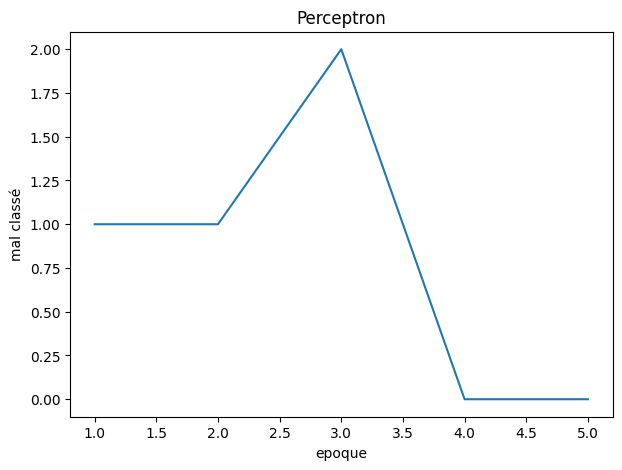

In [278]:
model = Perceptron(num_features=2)

X_train_tensor = X_train.clone().detach().to(device)
y_train_tensor = y_train.clone().detach().float().to(device)

n_errors = model.train(X_train_tensor, y_train_tensor, epochs=5)

print('Model parameters:')
print('  Weights: %s' % model.weights)
print('  Bias: %s' % model.bias)
# TODO : plot n_errors
plt.figure(figsize=(7, 5))
plt.plot(range(1, len(n_errors) + 1), n_errors)
plt.xlabel('epoque')
plt.ylabel('mal classé')
plt.title('Perceptron')
plt.show()

9. Evaluate the model (accuracy)

In [279]:
X_test_tensor = X_test.clone().detach().to(device)
y_test_tensor = y_test.clone().detach().float().to(device)

test_acc = model.evaluate(X_test_tensor, y_test_tensor)
print('Test set accuracy: %.2f%%' % (test_acc*100))

Test set accuracy: 93.33%


10. a. Plot the test points and the decision boundary of the perceptron.

    b. Under which condition on the data is the perceptron learning rule guaranteed to converge? Train your perceptron for 20 epochs on the **iris dataset of the Adaline part** and plot the number of errors per epoch. What do you observe? Compare with the Adaline and explain.

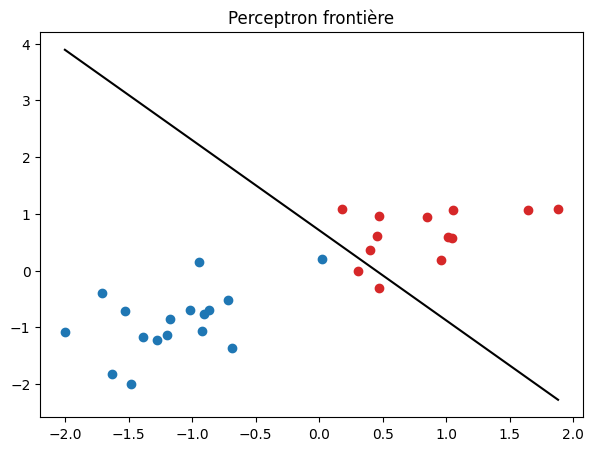

In [280]:
plt.figure(figsize=(7, 5))
X = X_test.detach().cpu()
y = y_test.detach().cpu().reshape(-1)
for label, color in [(0, 'tab:blue'), (1, 'tab:red')]:
    pts = X[y == label]
    plt.scatter(pts[:, 0], pts[:, 1], color=color)
w = model.weights.detach().cpu().reshape(-1)
b = model.bias.item()
xx = torch.linspace(X_test[:, 0].min().item(), X_test[:, 0].max().item(), 500)
yx = -(w[0] * xx + b) / w[1]
plt.plot(xx, yx, 'k-')
plt.title('Perceptron frontière')
plt.show()

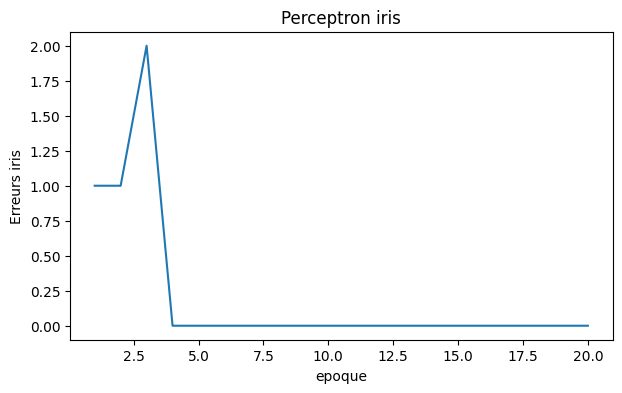

In [281]:
irisp = Perceptron(num_features=2)
iris_errors = irisp.train(X_train, y_train, epochs=20)
plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), iris_errors)
plt.xlabel('epoque'); plt.ylabel('Erreurs iris')
plt.title('Perceptron iris')
plt.show()

# Multi Layer Perceptron

Unlike the single-layer perceptron, the Multi Layer Perceptron models have hidden layers
between the input and the output layers. After every hidden layer, an activation function
is applied to introduce non-linearity.

11. Build a simple Multi Layer Perceptron model with one hidden layer.
After the hidden layer, we will use ReLU as activation before the information is sent to the output layer.
As an output activation function, we will use Sigmoid.

In [282]:
class MultilayerPerceptron(torch.nn.Module):
    def __init__(self, num_features, num_hidden_1):
        super(MultilayerPerceptron, self).__init__()
        # TODO
        self.hidden = torch.nn.Linear(num_features, num_hidden_1)
        self.output = torch.nn.Linear(num_hidden_1, 1)

    def forward(self, x):
        # TODO
        hidden = F.relu(self.hidden(x))
        out = torch.sigmoid(self.output(hidden))
        return out

12. Create a random dataset and assign binary labels {0,1}

In [283]:
def blob_label(y, label, loc): # assign labels
    target = np.copy(y)
    for l in loc:
        target[y == l] = label
    return target

x_train, y_train = make_blobs(n_samples=40, n_features=2, cluster_std=1.5, shuffle=True, random_state=0)
x_train = torch.FloatTensor(x_train)
y_train = torch.FloatTensor(blob_label(y_train, 0, [0]))
y_train = torch.FloatTensor(blob_label(y_train, 1, [1,2,3]))
x_test, y_test = make_blobs(n_samples=10, n_features=2, cluster_std=1.5, shuffle=True, random_state=1)
x_test = torch.FloatTensor(x_test)
y_test = torch.FloatTensor(blob_label(y_test, 0, [0]))
y_test = torch.FloatTensor(blob_label(y_test, 1, [1,2,3]))
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

torch.Size([40, 2])
torch.Size([40])
torch.Size([10, 2])
torch.Size([10])


13. Define the model with input dimension 2 and hidden dimension 10.
Since the task is to classify binary labels, we can use as criterion BCELoss (Binary Cross Entropy Loss).
The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

In [284]:
model = MultilayerPerceptron(2, 10)
criterion =   torch.nn.BCELoss()   # TODO
optimizer =  torch.optim.SGD(model.parameters(), lr=0.01)    # TODO

14. Check the test loss before the model training and compare it with the test loss after the training.

In [285]:
model.eval()
y_pred = model(x_test)
before_train = criterion(y_pred.squeeze(), y_test)
print('Test loss before training' , before_train.item())

Test loss before training 0.6911336183547974


In [286]:
model.train()
epoch = 20
for epoch in range(epoch):
    optimizer.zero_grad()
    y_pred = model(x_train)       # TODO
    loss = criterion(y_pred.squeeze(), y_train)       # TODO
    print('Epoch {}: train loss: {}'.format(epoch, loss.item()))
    # Backward pass
    loss.backward()
    optimizer.step()

Epoch 0: train loss: 0.674204409122467
Epoch 1: train loss: 0.67229163646698
Epoch 2: train loss: 0.6704350709915161
Epoch 3: train loss: 0.6686308979988098
Epoch 4: train loss: 0.6668758392333984
Epoch 5: train loss: 0.6651669144630432
Epoch 6: train loss: 0.6634979248046875
Epoch 7: train loss: 0.6618614196777344
Epoch 8: train loss: 0.6602628827095032
Epoch 9: train loss: 0.6586998701095581
Epoch 10: train loss: 0.6571704149246216
Epoch 11: train loss: 0.6556726694107056
Epoch 12: train loss: 0.6542046070098877
Epoch 13: train loss: 0.652764618396759
Epoch 14: train loss: 0.6513510942459106
Epoch 15: train loss: 0.6499595642089844
Epoch 16: train loss: 0.6485917568206787
Epoch 17: train loss: 0.6472464799880981
Epoch 18: train loss: 0.645916759967804
Epoch 19: train loss: 0.6445974111557007


In [287]:
model.eval()
y_pred = model(x_test)
after_train = criterion(y_pred.squeeze(), y_test)
print('Test loss after Training' , after_train.item())

Test loss after Training 0.6341489553451538


15. Write a function `accuracy(model, x, y)`. Re-initialise the model and train it for 500 epochs, recording at each epoch the train loss, the test loss and the test accuracy. Plot the two loss curves on the same figure and comment (under-fitting / over-fitting?).

In [288]:
def accuracy(model, x, y):
    y_pred = model(x).squeeze()
    classes = (y_pred > 0.5).float()
    bonnes = (classes == y).sum().item()
    return bonnes / len(y)

In [289]:
model = MultilayerPerceptron(2, 10)
criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

train_losses = []
test_losses = []
test_accs = []

for epoch in range(500):
    optimizer.zero_grad()
    y_pred_train = model(x_train)
    loss_train = criterion(y_pred_train.squeeze(), y_train)
    loss_train.backward()
    optimizer.step()

    with torch.no_grad():
        y_pred_test = model(x_test)
        loss_test = criterion(y_pred_test.squeeze(), y_test)

    train_losses.append(loss_train.item())
    test_losses.append(loss_test.item())
    test_accs.append(accuracy(model, x_test, y_test))

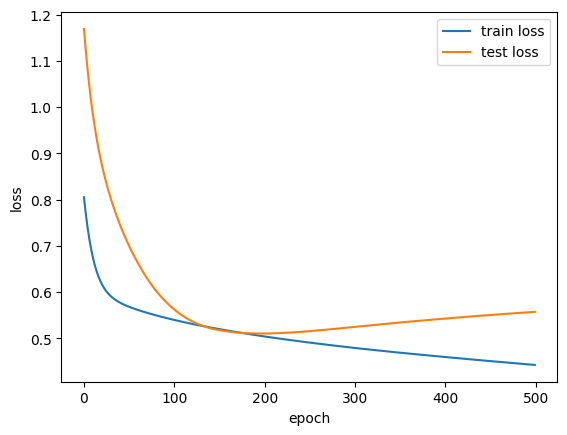

In [290]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label="train loss")
plt.plot(test_losses, label="test loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

16. Non linearly separable data. Generate a dataset with `make_moons(n_samples=300, noise=0.2, random_state=0)` (train/test split 70/30).

    a. Train a single-layer model (`nn.Linear(2, 1)` followed by a Sigmoid, BCE loss) and your MLP.

    b. For each model, plot the decision regions (hint: evaluate the model on a grid built with `np.meshgrid`, then use `plt.contourf`) and give the test accuracy.

    c. Conclude: what does the hidden layer bring?

In [291]:
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=300, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

x_train = torch.tensor(X_train, dtype=torch.float32)
x_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [292]:
linear_model = torch.nn.Sequential(torch.nn.Linear(2, 1), torch.nn.Sigmoid())
criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.1)

for epoch in range(1000):
    optimizer.zero_grad()
    y_pred = linear_model(x_train)
    loss = criterion(y_pred.squeeze(), y_train)
    loss.backward()
    optimizer.step()

In [293]:
mlp_model = MultilayerPerceptron(2, 10)
criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(mlp_model.parameters(), lr=0.1)

for epoch in range(1000):
    optimizer.zero_grad()
    y_pred = mlp_model(x_train)
    loss = criterion(y_pred.squeeze(), y_train)
    loss.backward()
    optimizer.step()

In [294]:
print("accuracy test modèle linéaire :", accuracy(linear_model, x_test, y_test))
print("accuracy test MLP :", accuracy(mlp_model, x_test, y_test))

accuracy test modèle linéaire : 0.8444444444444444
accuracy test MLP : 0.8555555555555555


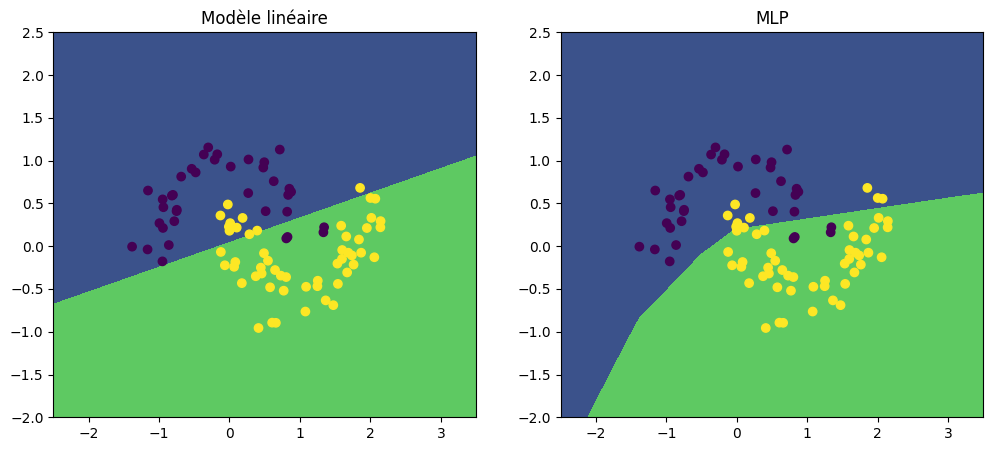

In [295]:
xx, yy = np.meshgrid(np.linspace(-2.5, 3.5, 200), np.linspace(-2, 2.5, 200))
grille = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

with torch.no_grad():
    zz_linear = linear_model(grille).reshape(xx.shape)
    zz_mlp = mlp_model(grille).reshape(xx.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.contourf(xx, yy, zz_linear, levels=[0, 0.5, 1])
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test)
plt.title("Modèle linéaire")

plt.subplot(1, 2, 2)
plt.contourf(xx, yy, zz_mlp, levels=[0, 0.5, 1])
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test)
plt.title("MLP")

plt.show()

Le modèle à une seule couche ne peut tracer qu’une une droite alors que MLP, grâce à sa couche cachée et ReLU, peut tracer une frontière courbe et son accuracy test est meilleure

17. In order to improve the model, you can try out different values for your
hyperparameters (hidden dimension size, number of epochs, learning rate). You can also
try changing the structure of your model (adding more hidden layers). Summarize your experiments in a table (configuration, test accuracy) and justify your best choice.

In [296]:
model_1 = MultilayerPerceptron(2, 50)
criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.1)

for epoch in range(1000):
    optimizer.zero_grad()
    y_pred = model_1(x_train)
    loss = criterion(y_pred.squeeze(), y_train)
    loss.backward()
    optimizer.step()

print("hidden 50 :", accuracy(model_1, x_test, y_test))

hidden 50 : 0.9333333333333333


In [297]:
model_2 = torch.nn.Sequential(
    torch.nn.Linear(2, 10),
    torch.nn.ReLU(),
    torch.nn.Linear(10, 10),
    torch.nn.ReLU(),
    torch.nn.Linear(10, 1),
    torch.nn.Sigmoid()
)
criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(model_2.parameters(), lr=0.1)

for epoch in range(1000):
    optimizer.zero_grad()
    y_pred = model_2(x_train)
    loss = criterion(y_pred.squeeze(), y_train)
    loss.backward()
    optimizer.step()

print("2 couches cachées :", accuracy(model_2, x_test, y_test))

2 couches cachées : 0.8888888888888888


In [298]:
model_3 = MultilayerPerceptron(2, 10)
criterion = torch.nn.BCELoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr=0.5)

for epoch in range(1000):
    optimizer.zero_grad()
    y_pred = model_3(x_train)
    loss = criterion(y_pred.squeeze(), y_train)
    loss.backward()
    optimizer.step()

print("lr 0.5 :", accuracy(model_3, x_test, y_test))

lr 0.5 : 0.9888888888888889


In [299]:
noms = ["hidden 10\nlr 0.1 (Q16)", "hidden 50\nlr 0.1", "2 couches\n(10-10)", "hidden 10\nlr 0.5"]

acc_ref = accuracy(mlp_model, x_test, y_test)
acc_1 = accuracy(model_1, x_test, y_test)
acc_2 = accuracy(model_2, x_test, y_test)
acc_3 = accuracy(model_3, x_test, y_test)
accs = [acc_ref, acc_1, acc_2, acc_3]

print("Configuration | Test accuracy")
print("MLP hidden 10, lr 0.1 (Q16) |", acc_ref)
print("MLP hidden 50, lr 0.1 |", acc_1)
print("2 couches cachées (10-10), lr 0.1 |", acc_2)
print("MLP hidden 10, lr 0.5 |", acc_3)

Configuration | Test accuracy
MLP hidden 10, lr 0.1 (Q16) | 0.8555555555555555
MLP hidden 50, lr 0.1 | 0.9333333333333333
2 couches cachées (10-10), lr 0.1 | 0.8888888888888888
MLP hidden 10, lr 0.5 | 0.9888888888888889


Les résultats parle d'eux mêmes, Le meilleur est obtenu avec lr = 0.5, avec MLP hidden 50 on obtient également une bonne amélioration.